# 03 - Modelling

Baselines first: Logistic Regression and Decision Tree. 80/20 split grouped by customer,
tuned with 5-fold CV on the train set. Test set is left alone until the final model.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

from train import models, X_train, y_train, groups, cv
print(X_train.shape, y_train.mean().round(3))

(2721, 32) 0.234


In [2]:
probs = {}
for name, (pipe, params) in models.items():
    grid = GridSearchCV(pipe, params, scoring="roc_auc", cv=cv)
    grid.fit(X_train, y_train, groups=groups)
    probs[name] = cross_val_predict(grid.best_estimator_, X_train, y_train, groups=groups,
                                    cv=cv, method="predict_proba")[:, 1]
    models[name] = grid.best_estimator_
    print(name, grid.best_params_, "AUC:", round(roc_auc_score(y_train, probs[name]), 3))

logistic_regression {'model__C': 0.01} AUC: 0.74


decision_tree {'model__max_depth': 5, 'model__min_samples_leaf': 60} AUC: 0.7


In [3]:
for name, prob in probs.items():
    print(name)
    print(classification_report(y_train, prob >= 0.5, digits=3))

logistic_regression
              precision    recall  f1-score   support

           0      0.870     0.707     0.780      2084
           1      0.405     0.653     0.500       637

    accuracy                          0.694      2721
   macro avg      0.637     0.680     0.640      2721
weighted avg      0.761     0.694     0.714      2721

decision_tree
              precision    recall  f1-score   support

           0      0.863     0.678     0.759      2084
           1      0.381     0.648     0.480       637

    accuracy                          0.671      2721
   macro avg      0.622     0.663     0.619      2721
weighted avg      0.750     0.671     0.694      2721



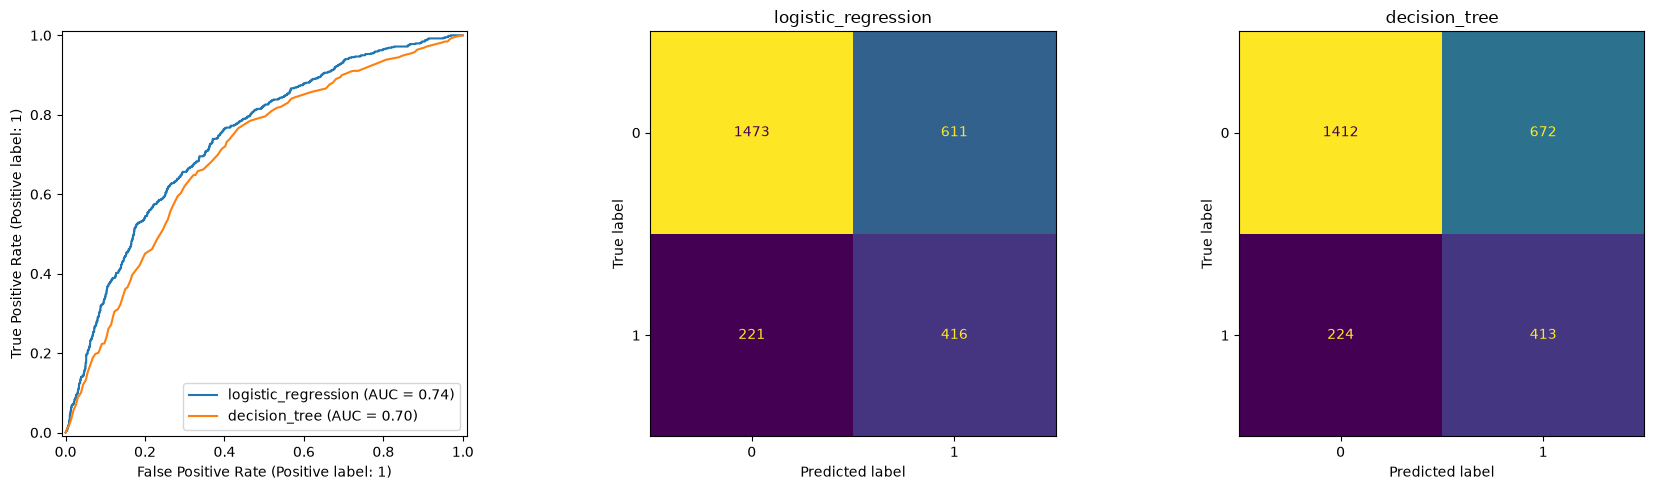

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, prob in probs.items():
    RocCurveDisplay.from_predictions(y_train, prob, name=name, ax=axes[0])
for ax, (name, prob) in zip(axes[1:], probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_train, prob >= 0.5, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()

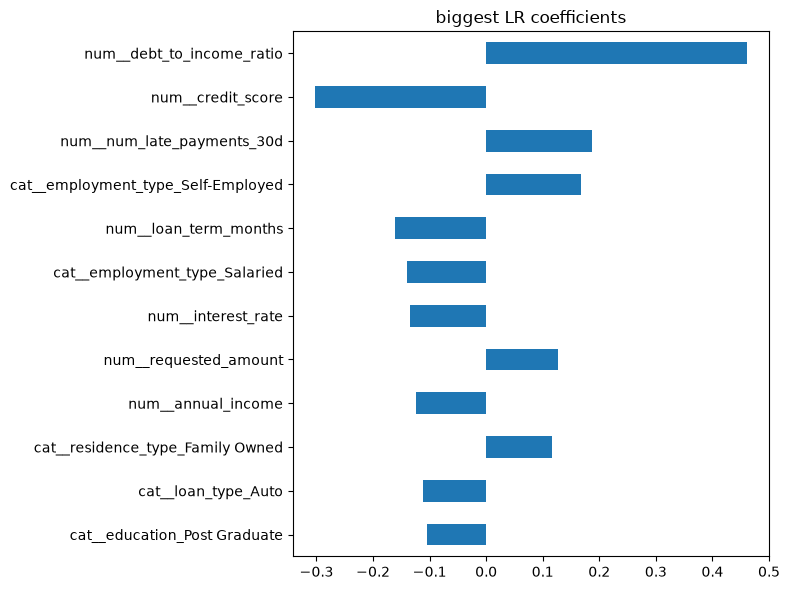

In [5]:
lr = models["logistic_regression"]
coefs = pd.Series(lr["model"].coef_[0], index=lr["prep"].get_feature_names_out())
coefs.sort_values(key=abs).tail(12).plot.barh(figsize=(8, 6), title="biggest LR coefficients")
plt.tight_layout()

## Class imbalance

Only ~23% of loans default. Checking what happens without `class_weight="balanced"`.

In [6]:
lr_no_weight = models["logistic_regression"].set_params(model__class_weight=None)
prob = cross_val_predict(lr_no_weight, X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
print("AUC:", round(roc_auc_score(y_train, prob), 3))
print(classification_report(y_train, prob >= 0.5, digits=3))
models["logistic_regression"].set_params(model__class_weight="balanced");

AUC: 0.739
              precision    recall  f1-score   support

           0      0.783     0.964     0.864      2084
           1      0.513     0.126     0.202       637

    accuracy                          0.767      2721
   macro avg      0.648     0.545     0.533      2721
weighted avg      0.720     0.767     0.709      2721



AUC is the same but recall on defaults drops from ~0.65 to ~0.13, so the model barely
flags anyone. Keeping `class_weight="balanced"`, no need for SMOTE.

## Outliers

A lot of the money columns are right skewed (`loan_to_income` goes up to 54). Trying a log
transform on the skewed columns for logistic regression.

In [7]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from features import num_cols, cat_cols

skewed = [c for c in num_cols if X_train[c].skew() > 2]
others = [c for c in num_cols if c not in skewed]
print(skewed)

prep = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), others),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
lr_log = Pipeline([("prep", prep), ("model", LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000))])
prob = cross_val_predict(lr_log, X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
print("AUC with log:", round(roc_auc_score(y_train, prob), 3), "vs", round(roc_auc_score(y_train, probs["logistic_regression"]), 3))

['annual_income', 'num_late_payments_90d', 'num_defaults_prior', 'bankruptcies', 'requested_amount', 'loan_term_months', 'loan_to_income', 'total_inflow', 'total_outflow', 'emi_outflow', 'avg_balance', 'inflow_outflow_ratio']


AUC with log: 0.741 vs 0.74


Basically no difference (clipping at the 1st/99th percentile was the same), so leaving the
outliers as they are. Tree models don't care about them anyway.

## Notes

- Logistic Regression is better than the tree (AUC ~0.74 vs ~0.70).
- Recall at 0.5 is ~0.65, under the 0.70 target. Changing the threshold will help but AUC
  still needs to get closer to 0.80, so Random Forest / XGBoost next.
- Biggest drivers: debt-to-income, credit score, 30-day late payments, income and
  employment type (self-employed riskier, salaried safer).